---
date: "2026-10-16"
date-modified: last-modified
format:
  html:
    toc: true
---


# Case Study: The Dimension Limit of Embedding-Based Retrieval

## Why I Read This Paper

The default fix for almost everything in ML today is mechanical: more data, a bigger model. Dense retrieval is no exception. When it misses a document, we add training pairs, mine harder negatives or swap in a larger encoder. Yet most production search stacks, including the one I worked on, still keep good old BM25 next to the dense retriever. I had always filed that under "a training gap that will close eventually".

This paper says otherwise, and the claim is far from obvious: **some failures of single-vector retrieval cannot be trained away.** If queries and documents are vectors in $\mathbb{R}^d$ ranked by inner product, then for a fixed $d$ there are top-$k$ result sets that **no query can ever return**. That holds even with perfectly optimized embeddings and even for very simple queries. The bottleneck is the geometry of the embedding space, not the data or the model.

I like results like this because they mark where scaling stops helping. Two practical consequences:

* **Some fixes have to be architectural.** A larger $d$, multi-vector models, cross-encoders, or sparse/hybrid retrieval, rather than more of the same.
* **Evaluation can hide it.** A benchmark tests only a tiny slice of the possible top-$k$ combinations, so a model can score well and still be unable to represent most of them.

The core idea in one sentence: **every distinct top-$k$ answer needs its own query direction, and a $d$-dimensional space only has room for so many well-separated directions.** This note builds that up from a 2D picture to the theorem, then checks it on the paper's LIMIT data.

## 1\. Setup and Notation

* $[n] = \{1, \dots, n\}$: document indices. Document $i$ has a unit vector $v_i \in \mathbb{R}^d$.
* Queries are unit vectors $u \in \mathbb{R}^d$; the score of document $i$ is $\langle u, v_i \rangle \in [-1, 1]$.
* $S \subseteq [n]$ with $|S| = k$: one possible top-$k$ answer. There are $\binom{n}{k}$ of them ([binomial coefficient](binomial-coefficient.ipynb)).
* $\gamma > 0$: the required margin.

::: {#def-realized-margin}
## Realized with Margin $\gamma$

A $k$-subset $S \subseteq [n]$ is **realized with margin $\gamma$** if there is a unit query $u_S$ such that

$$
\min_{i \in S} \langle u_S, v_i \rangle \;\geq\; \max_{j \notin S} \langle u_S, v_j \rangle + 2\gamma .
$$
:::

::: {.callout-note}
## Intuition: Realized = Singled Out

The documents in $S$ need not be close to each other. What matters is that **some query
direction scores every document in $S$ above every document outside $S$, with a clean
gap of $2\gamma$**. Since scores lie in $[-1,1]$, this is only possible for $0 < \gamma \leq 1$.
:::


## 2\. Realization in 2D: Not Every Answer Is Reachable

Before any formula, here is the smallest example where the limit shows up.

Put $n=4$ documents on the unit circle at $0°, 90°, 180°, 270°$ and rotate a query $u$
through a full turn. Its top-2 is always the two documents closest in angle, i.e. a pair
of **neighbours**.

For opposite points $v_1, v_3$ the scores are $\cos\theta$ and $-\cos\theta$, so when one is
high the other is low: $\{1,3\}$ and $\{2,4\}$ are never realized. Only $4$ of the
$\binom{4}{2}=6$ pairs are reachable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from itertools import combinations

DOC, QRY, OK, BAD, MUTED = "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9a9a9a"

V = np.array([[1, 0], [0, 1], [-1, 0], [0, -1]], dtype=float)  # 4 documents on the unit circle
pairs = list(combinations(range(4), 2))  # all 6 possible top-2 sets
thetas = np.linspace(np.pi / 4, np.pi / 4 + 2 * np.pi, 180, endpoint=False)
HOLD = 40  # frames to hold at the end

fig, (ax, axb) = plt.subplots(1, 2, figsize=(7, 4.5),
                              gridspec_kw={"width_ratios": [1, 1.1]})
fig.suptitle(r"Which top-2 sets can a query $u$ realize in $d=2$?", fontsize=12)
fig.subplots_adjust(bottom=0.32, wspace=0.35)

# left: circle, documents, rotating query
ax.set_aspect("equal"); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5); ax.axis("off")
t = np.linspace(0, 2 * np.pi, 300)
ax.plot(np.cos(t), np.sin(t), color=MUTED, lw=1.5)
docs = ax.scatter(V[:, 0], V[:, 1], s=120, c=DOC, zorder=3)
for i, (x, y) in enumerate(V):
    ax.text(1.25 * x, 1.25 * y, f"$v_{i+1}$", ha="center", va="center",
            fontsize=12, color=DOC)
arrow = ax.annotate("", xy=(1, 0), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=QRY, lw=2.5,
                                   mutation_scale=18))
ulab = ax.text(0, 0, "$u$", color=QRY, fontsize=13)

# right: scores + checklist of pairs
bars = axb.barh(range(4), np.zeros(4), color=MUTED)
axb.set_yticks(range(4), [f"$v_{i+1}$" for i in range(4)], fontsize=10)
axb.set_ylim(3.6, -0.6); axb.set_xlim(-1.1, 1.1); axb.axvline(0, color="k", lw=0.8)
axb.set_xlabel(r"score $\langle u, v_i\rangle$", fontsize=10); axb.grid(alpha=0.3, ls="--")

fig.text(0.42, 0.17, "top-2 sets seen:", fontsize=10)
pair_txt = [fig.text(0.60 + 0.10 * (k % 3), 0.17 - 0.07 * (k // 3),
                     rf"$\{{{a+1},{b+1}\}}$", color=MUTED, fontsize=11)
            for k, (a, b) in enumerate(pairs)]
verdict = fig.text(0.5, 0.03, "", ha="center", fontsize=10, color=BAD)

seen = set()

def update(f):
    th = thetas[min(f, len(thetas) - 1)]
    u = np.array([np.cos(th), np.sin(th)])
    s = V @ u
    order = np.argsort(-s)
    gap = s[order[1]] - s[order[2]]
    top = {int(order[0]), int(order[1])} if gap > 0.03 else set()  # realized with a visible margin
    if top:
        seen.add(tuple(sorted(top)))
    arrow.xy = tuple(0.97 * u)
    ulab.set_position(0.6 * u + 0.13 * np.array([-u[1], u[0]]))
    docs.set_color([OK if i in top else DOC for i in range(4)])
    for i, b in enumerate(bars):
        b.set_width(s[i]); b.set_color(OK if i in top else MUTED)
    for k, p in enumerate(pairs):
        if p in seen:
            pair_txt[k].set_color(OK)
        elif f >= len(thetas):
            pair_txt[k].set_color(BAD)
    if f >= len(thetas):
        verdict.set_text("opposite points never share the top-2: only 4 of 6")
    return []

anim = FuncAnimation(fig, update, frames=len(thetas) + HOLD, interval=50)
plt.close(fig)
HTML(anim.to_html5_video().replace("<video ", "<video autoplay loop muted "))


## 3\. A Lemma: Realization Separates Every Inside–Outside Pair

The 2D picture shows the effect. To prove it in any dimension we need one small step first: realization is stated with a min and a max, but the proof needs a statement about individual documents.

::: {#lem-pairwise-gap}
## Pairwise Gap

If $S$ is realized with margin $\gamma$ by $u_S$, then for every $i \in S$ and every $j \notin S$:

$$
\langle u_S,\, v_i - v_j \rangle \;\geq\; 2\gamma .
$$
:::

::: {.callout-tip collapse="true"}
## Proof of the Pairwise Gap Lemma

A single element of a set is at least its minimum and at most its maximum. So for $i \in S$, $j \notin S$:

$$
\begin{aligned}
\langle u_S, v_i \rangle
  &\geq \min_{i' \in S} \langle u_S, v_{i'} \rangle && \text{($i \in S$)} \\
  &\geq \max_{j' \notin S} \langle u_S, v_{j'} \rangle + 2\gamma && \text{(definition of realized)} \\
  &\geq \langle u_S, v_j \rangle + 2\gamma && \text{($j \notin S$)}.
\end{aligned}
$$

By linearity of the inner product, $\langle u_S, v_i \rangle - \langle u_S, v_j \rangle = \langle u_S, v_i - v_j \rangle \geq 2\gamma$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: From Min/Max to Every Pair

The definition compares only the *weakest* insider with the *strongest* outsider.
Since every other pair is further apart, **every** insider beats **every** outsider
by at least $2\gamma$.
:::


## 4\. The Dimension Lower Bound

Now the main result: if a retriever must be able to return *every* top-$k$ set, how many dimensions does it need?

::: {#thm-dimension-lower-bound}
## Dimension Lower Bound

Let $1 \leq k < n$. If every $k$-subset $S \subseteq [n]$ is realized with margin $\gamma$, then

$$
\binom{n}{k} \;\leq\; \left(1 + \frac{1}{\gamma}\right)^d,
\qquad\text{hence}\qquad
d \;\geq\; \frac{\log \binom{n}{k}}{\log(1 + 1/\gamma)} .
$$
:::

::: {.callout-tip collapse="true"}
## Proof of the Dimension Lower Bound

**Step 1: distinct answers need far-apart queries.** Take $S \neq T$. Both have $k$ elements, so there exist $i \in S \setminus T$ and $j \in T \setminus S$. By @lem-pairwise-gap applied to $S$ (with $i \in S$, $j \notin S$) and to $T$ (with $j \in T$, $i \notin T$):

$$
\langle u_S, v_i - v_j \rangle \geq 2\gamma,
\qquad
\langle u_T, v_j - v_i \rangle \geq 2\gamma .
$$

Adding them, using linearity:

$$
\langle u_S - u_T,\, v_i - v_j \rangle \geq 4\gamma .
$$

By the [Cauchy–Schwarz inequality](Cauchy-Schwarz-inequality.ipynb) and the [triangle inequality](triangle-inequality.ipynb), $\|v_i - v_j\| \leq \|v_i\| + \|v_j\| = 2$, so

$$
4\gamma \leq \|u_S - u_T\| \, \|v_i - v_j\| \leq 2\,\|u_S - u_T\|
\quad\Longrightarrow\quad
\|u_S - u_T\| \geq 2\gamma .
$$

**Step 2: the balls are disjoint.** Let $B(u, \gamma) = \{x : \|x - u\| < \gamma\}$. If some $x$ were in both $B(u_S, \gamma)$ and $B(u_T, \gamma)$, then by the triangle inequality $\|u_S - u_T\| \leq \|u_S - x\| + \|x - u_T\| < 2\gamma$, contradicting Step 1. So the $M = \binom{n}{k}$ balls are pairwise disjoint.

**Step 3: count volumes.** Since $\|u_S\| = 1$, every $x \in B(u_S, \gamma)$ has $\|x\| \leq \|u_S\| + \|x - u_S\| < 1 + \gamma$, so each ball lies inside $B(0, 1 + \gamma)$. Disjoint sets inside a bigger set have total volume at most the bigger one's:

$$
M \cdot \mathrm{vol}(B_d(\gamma)) \leq \mathrm{vol}(B_d(1 + \gamma)).
$$

With $\mathrm{vol}(B_d(r)) = C_d\, r^d$, the constant $C_d$ cancels:

$$
M \gamma^d \leq (1 + \gamma)^d
\quad\Longrightarrow\quad
\binom{n}{k} \leq \left(\frac{1+\gamma}{\gamma}\right)^d = \left(1 + \frac{1}{\gamma}\right)^d .
$$

Taking logarithms gives the bound on $d$. $\blacksquare$
:::

::: {.callout-note}
## Intuition: Not Enough Room

Every top-$k$ answer needs its own query, the queries must be $2\gamma$ apart, and $\mathbb{R}^d$
only has room for about $(1 + 1/\gamma)^d$ such points. The room grows exponentially in $d$,
so $d$ must grow like $\log \binom{n}{k}$.
:::

::: {.callout-warning}
## A Very Loose Bound

For $n = 10^6$, $k = 2$, $\gamma = 0.1$ it only gives $d \geq 12$. Its value is the *shape* of
the result (no amount of model scale replaces $d$), not the number.
:::


### 4.1\. The Required Dimension Grows Linearly in $k$

::: {#cor-linear-in-k}
## Linear Growth in $k$

Under the assumptions of @thm-dimension-lower-bound,

$$
d \;\geq\; \frac{k \log(n/k)}{\log(1 + 1/\gamma)} .
$$
:::

::: {.callout-tip collapse="true"}
## Proof of Linear Growth in $k$

Write the [binomial coefficient](binomial-coefficient.ipynb) as a product:

$$
\binom{n}{k} = \prod_{i=0}^{k-1} \frac{n-i}{k-i} .
$$

Each factor satisfies $\frac{n-i}{k-i} \geq \frac{n}{k}$, because $k(n-i) \geq n(k-i) \iff ni \geq ki$, which holds since $n \geq k$. Hence $\binom{n}{k} \geq (n/k)^k$, so $\log\binom{n}{k} \geq k \log(n/k)$. Substituting into @thm-dimension-lower-bound gives the claim. $\blacksquare$
:::

::: {.callout-note}
## Intuition: Bigger $k$ Is Much Harder

In the worst case, supporting every top-$20$ set needs roughly ten times the dimension that supporting every top-$2$ set does. Asking for longer result lists, or for queries that combine several conditions, eats dimensions fast.
:::


## 5\. The Packing Argument in 2D

The whole proof in one picture.

The animation follows the three proof steps with $\gamma = 0.25$: queries on the unit
circle at least $2\gamma$ apart, disjoint balls of radius $\gamma$ around them (a 13th
query would overlap), and all balls inside $B(0, 1+\gamma)$.

In [2]:
from matplotlib.patches import Circle

g, M = 0.25, 12  # margin gamma, number of queries
angs = 2 * np.pi * np.arange(M) / M + 0.1
Q = np.c_[np.cos(angs), np.sin(angs)]  # neighbours are 2 sin(pi/12) = 0.52 >= 2*gamma apart
x_a = (angs[5] + angs[6]) / 2  # where we try to squeeze in one more query
X = np.array([np.cos(x_a), np.sin(x_a)])

# timeline (frames): queries appear -> balls grow -> extra ball fails -> big ball -> bound
T_Q, T_B, T_X, T_BIG, T_END = 36, 66, 96, 126, 190

fig, ax = plt.subplots(figsize=(7, 5))
fig.subplots_adjust(left=0.02, right=0.98)
ax.set_aspect("equal"); ax.set_xlim(-1.5, 3.6); ax.set_ylim(-1.45, 1.45); ax.axis("off")
fig.suptitle(rf"Proof idea: queries are packed balls ($\gamma={g}$)", fontsize=12)

t = np.linspace(0, 2 * np.pi, 300)
ax.plot(np.cos(t), np.sin(t), color=MUTED, lw=1.5)
ax.text(-0.22, -0.05, r"$\|u\|=1$", color=MUTED, fontsize=10)

dots = ax.scatter(Q[:, 0], Q[:, 1], s=25, c=QRY, zorder=4)
balls = [ax.add_patch(Circle(q, 0, fc=QRY, ec=QRY, alpha=0.25, lw=1.5)) for q in Q]
xball = ax.add_patch(Circle(X, 0, fc=BAD, ec=BAD, alpha=0.3, lw=2))
xtext = ax.text(*(1.45 * X), "overlap!", color=BAD, fontsize=10, ha="center", alpha=0)
big = ax.add_patch(Circle((0, 0), 1 + g, fill=False, ec=DOC, ls="--", lw=2, alpha=0))
bigtxt = ax.text(-1.48, 1.2, r"$B(0,\,1+\gamma)$", color=DOC, fontsize=10, alpha=0)

lines = [
    (T_Q,       r"1) $S\neq T \;\Rightarrow\; \|u_S-u_T\|\geq 2\gamma$"),
    (T_B,       r"2) balls $B(u_S,\gamma)$ are disjoint"),
    (T_BIG,     r"3) all inside $B(0,1+\gamma)$:"),
    (T_BIG + 20, rf"$\Rightarrow\; M \leq (1+1/\gamma)^2 = {(1 + 1/g)**2:.0f}$"),
    (T_BIG + 40, r"in $\mathbb{R}^d$: $\binom{{n}}{{k}} \leq (1+1/\gamma)^d$"),
]
texts = [ax.text(1.45, 1.05 - 0.38 * i, s, fontsize=11, alpha=0)
         for i, (_, s) in enumerate(lines)]
texts[-1].set_color(OK)

def ramp(f, a, b):  # goes 0 -> 1 between frames a and b
    return float(np.clip((f - a) / (b - a), 0, 1))

def update(f):
    shown = int(np.ceil(M * ramp(f, 0, T_Q - 6)))
    dots.set_facecolors([QRY if i < shown else "none" for i in range(M)])
    dots.set_edgecolors([QRY if i < shown else "none" for i in range(M)])
    for b in balls:
        b.set_radius(g * ramp(f, T_Q, T_B - 6))
    xball.set_radius(g * ramp(f, T_B + 4, T_B + 14) * (1 - ramp(f, T_X - 6, T_X)))
    xtext.set_alpha(1.0 if (T_B + 10 < f < T_X - 4) else 0.0)
    big.set_alpha(ramp(f, T_X, T_X + 15)); bigtxt.set_alpha(ramp(f, T_X, T_X + 15))
    for (start, _), txt in zip(lines, texts):
        txt.set_alpha(ramp(f, start - 8, start))
    return []

anim = FuncAnimation(fig, update, frames=T_END, interval=50)
plt.close(fig)
HTML(anim.to_html5_video().replace("<video ", "<video autoplay loop muted "))


::: {.callout-warning}
## Why 25 but Only 12?

The volume bound allows $25$ balls, but only $12$ fit, because the proof ignores
that the queries lie *on* the sphere, not anywhere inside the big ball. That slack
is why the bound is loose.
:::


## 6\. The Best Case on Real Data: LIMIT

The theorem is about *existence*. To make it concrete, the paper builds **LIMIT**: documents like "Geneva Durben likes Quokkas, Tapirs, Sapphires, …" and queries like "Who likes Quokkas?", each with exactly two relevant people. Linguistically the task is trivial. Combinatorially it is not: in the small version, the $1000$ queries ask for $1000$ of the $\binom{46}{2} = 1035$ possible pairs of documents.

I compare two retrievers on **LIMIT-small** (46 documents, 1000 queries), scoring each query as correct only if its top-2 is exactly the relevant pair:

* **BM25**, plain keyword matching (see [TF-IDF and BM25](cs-tfidf-bm25-search-relevance.ipynb)).
* **Free embeddings**, the *best case for any embedding model*. There is no encoder: the query and document vectors are optimized directly on the test answers themselves, so the only constraint left is the dimension $d$. No trained model can do better.

The second panel runs the same free-embedding optimization on *all* $\binom{n}{2}$ pairs of $n$ documents and records the largest $n$ that still fits in dimension $d$ (the **critical $n$**).

In [3]:
import json

# LIMIT-small from github.com/google-deepmind/limit (CC-BY 4.0), saved under ../data/limit-small/
def read_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]

DATA = "../data/limit-small/"
corpus, queries, qrels = (read_jsonl(DATA + f) for f in ("corpus.jsonl", "queries.jsonl", "qrels.jsonl"))

doc_idx = {d["_id"]: i for i, d in enumerate(corpus)}
q_idx = {q["_id"]: i for i, q in enumerate(queries)}
relevant = [set() for _ in queries]
for r in qrels:
    relevant[q_idx[r["query-id"]]].add(doc_idx[r["corpus-id"]])

print(f"{len(corpus)} documents, {len(queries)} queries, "
      f"{len({tuple(sorted(r)) for r in relevant})} distinct relevant pairs")
print("query :", queries[0]["text"], "->", [corpus[i]["_id"] for i in relevant[0]])
print("doc   :", corpus[0]["text"][:120], "...")

46 documents, 1000 queries, 1000 distinct relevant pairs
query : Who likes Joshua Trees? -> ['Geneva Durben', 'Dorathea Bastress']
doc   : Geneva Durben likes Quokkas, River Otters, Tapirs, Asymmetry, Snow Leopards, Hydrangeas, Crocheting, Symphonies, Bassoon ...


BM25 exact top-2: 98.4%
free embeddings d= 2: 0.4%
free embeddings d= 3: 2.6%
free embeddings d= 4: 28.9%
free embeddings d= 5: 31.5%
free embeddings d= 6: 81.2%
free embeddings d= 7: 98.6%
free embeddings d= 8: 100.0%
free embeddings d= 9: 100.0%
free embeddings d=10: 100.0%
critical n: {2: 3, 3: 4, 4: 10, 5: 16, 6: 25, 8: 54}


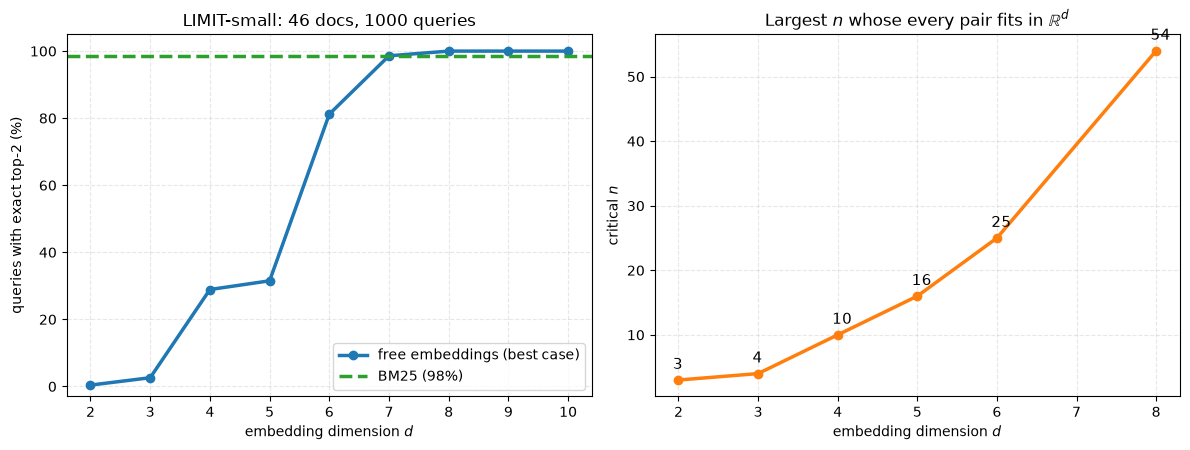

In [4]:
import re
from collections import Counter

# ---------- BM25 ----------
def tokenize(s):
    return re.findall(r"[a-z0-9]+", s.lower())

docs = [tokenize(d["text"]) for d in corpus]
N, avg_len = len(docs), np.mean([len(x) for x in docs])
df = Counter(w for x in docs for w in set(x))
idf = {w: np.log(1 + (N - c + 0.5) / (c + 0.5)) for w, c in df.items()}
tfs = [Counter(x) for x in docs]

def bm25(query, k1=1.2, b=0.75):
    q = tokenize(query)
    return np.array([sum(idf[w] * tf[w] * (k1 + 1) / (tf[w] + k1 * (1 - b + b * len(x) / avg_len))
                         for w in q if w in tf) for tf, x in zip(tfs, docs)])

bm25_top2 = np.argsort(-np.array([bm25(q["text"]) for q in queries]), axis=1)[:, :2]
bm25_acc = np.mean([set(t) == r for t, r in zip(bm25_top2, relevant)])

# ---------- free embeddings: optimize the vectors themselves (best case for any model) ----------
def free_embedding_accuracy(R, n, d, steps=3000, lr=0.05, tau=0.05, seed=0):
    """Fit unit query/document vectors in R^d to relevance sets R with softmax cross-entropy + Adam.
    Returns the fraction of queries whose top-k is exactly their relevant set."""
    rng = np.random.default_rng(seed)
    m, k = len(R), len(next(iter(R)))
    Y = np.zeros((m, n))
    for a, r in enumerate(R):
        Y[a, list(r)] = 1 / len(r)
    params = [rng.standard_normal((m, d)), rng.standard_normal((n, d))]
    m1, m2 = [np.zeros_like(p) for p in params], [np.zeros_like(p) for p in params]

    def normalize(X):
        l = np.linalg.norm(X, axis=1, keepdims=True)
        return X / l, l

    for t in range(1, steps + 1):
        (Qn, lq), (Dn, ld) = normalize(params[0]), normalize(params[1])
        S = Qn @ Dn.T / tau
        P = np.exp(S - S.max(1, keepdims=True)); P /= P.sum(1, keepdims=True)
        G = (P - Y) / (m * tau)                                   # dLoss/dScores
        gQn, gDn = G @ Dn, G.T @ Qn
        grads = [(gQn - (gQn * Qn).sum(1, keepdims=True) * Qn) / lq,   # back through normalization
                 (gDn - (gDn * Dn).sum(1, keepdims=True) * Dn) / ld]
        for p, g, a, b in zip(params, grads, m1, m2):                  # Adam
            a *= 0.9; a += 0.1 * g; b *= 0.999; b += 0.001 * g * g
            p -= lr * (a / (1 - 0.9 ** t)) / (np.sqrt(b / (1 - 0.999 ** t)) + 1e-8)
        if t % 250 == 0 or t == steps:
            top = np.argsort(-(normalize(params[0])[0] @ normalize(params[1])[0].T), axis=1)[:, :k]
            acc = np.mean([set(top[a]) == R[a] for a in range(m)])
            if acc == 1.0:
                return acc
    return acc

dims = list(range(2, 11))
limit_acc = [free_embedding_accuracy(relevant, len(corpus), d) for d in dims]

def critical_n(d):
    """Largest n such that all C(n,2) pairs fit in R^d (best of 2 random restarts)."""
    n = d + 1
    while max(free_embedding_accuracy([set(p) for p in combinations(range(n + 1), 2)], n + 1, d, seed=s)
              for s in range(2)) == 1.0:
        n += 1
    return n

crit_dims = [2, 3, 4, 5, 6, 8]
crit_n = [critical_n(d) for d in crit_dims]          # takes ~1-2 minutes on a laptop CPU

print(f"BM25 exact top-2: {bm25_acc:.1%}")
for d, a in zip(dims, limit_acc):
    print(f"free embeddings d={d:2d}: {a:.1%}")
print("critical n:", dict(zip(crit_dims, crit_n)))

# ---------- plot ----------
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6))
a1.plot(dims, np.array(limit_acc) * 100, "o-", color=DOC, lw=2.5, label="free embeddings (best case)")
a1.axhline(bm25_acc * 100, color=OK, lw=2.5, ls="--", label=f"BM25 ({bm25_acc:.0%})")
a1.set(xlabel="embedding dimension $d$", ylabel="queries with exact top-2 (%)",
       title="LIMIT-small: 46 docs, 1000 queries", ylim=(-3, 105))
a1.legend(loc="lower right"); a1.grid(alpha=0.3, ls="--")

a2.plot(crit_dims, crit_n, "o-", color=QRY, lw=2.5)
for d, n in zip(crit_dims, crit_n):
    a2.annotate(str(n), (d, n), textcoords="offset points", xytext=(-4, 8), fontsize=11)
a2.set(xlabel="embedding dimension $d$", ylabel="critical $n$",
       title="Largest $n$ whose every pair fits in $\\mathbb{R}^d$")
a2.grid(alpha=0.3, ls="--")
plt.tight_layout(); plt.show()


::: {.callout-note}

## Reading the Results

* **BM25 solves almost every query** with no training at all: it matches the attribute word, and keyword space has as many dimensions as the vocabulary.
* **Even the best-case embedding needs $d \geq 8$** for these 46 documents, although it was optimized on the answers themselves. Below that, no amount of training helps: the geometry is the bottleneck.
* **The two smallest critical-$n$ values match the earlier pictures:** $n = 3$ in 2D (four points already fail, as in the circle animation) and $n = 4$ in 3D (the regular tetrahedron).
* **Critical $n$ grows fast with $d$**, so 1024 dimensions are plenty for 46 documents *in the best case*. Real models are not free embeddings: they must map text to vectors and generalize to unseen queries. On the full LIMIT (50k documents) the paper reports that state-of-the-art embedding models with up to 4096 dimensions struggle, while BM25 performs very well.
:::

::: {.callout-warning}
## My Numbers vs. the Paper's

The paper fits a cubic to its critical-$n$ curve and extrapolates about $4$ million documents at $d = 1024$ for $k = 2$. My small-$d$ values come out somewhat higher than that fit; the optimizer, temperature and stopping rule all move them. The trend, not the exact constant, is the point.
:::


## 7\. What I Take Away

* **Scaling has a ceiling here.** More data and bigger encoders cannot add representable top-$k$ sets beyond what $\mathbb{R}^d$ allows. The fix is architectural.
* **The limit is worst-case, but realistic queries hit it.** Instruction-following, logical ("A and B") and attribute-matching queries can ask for arbitrary combinations of documents, which is exactly what LIMIT does.
* **The bound is loose, the shape is not.** The required $d$ grows like $\log\binom{n}{k}$, roughly linearly in $k$.
* **Keep BM25 next to your dense retriever.** Lexical, multi-vector and cross-encoder models are not bound by a single inner product in $\mathbb{R}^d$. In a hybrid stack, BM25 is not legacy; it covers a gap the geometry creates.

---

> **References & Acknowledgments:**
>
> This case study is a guided reading of *On the Theoretical Limitations of Embedding-Based Retrieval* by Orion Weller, Michael Boratko, Iftekhar Naim and Jinhyuk Lee (Google DeepMind & Johns Hopkins University), [arXiv:2508.21038](https://arxiv.org/abs/2508.21038), ICLR 2026. The setup, the definition of realization with margin, the dimension lower bound and its corollary (Section 3), the free-embedding experiment (Section 4) and the LIMIT dataset (Section 5) follow the paper. The 2D examples, the pairwise-gap lemma as a separate step, the animations, my re-implementation of the experiments and the commentary are my own.
>
> LIMIT-small data from [github.com/google-deepmind/limit](https://github.com/google-deepmind/limit), © 2025 Google LLC, licensed under [CC-BY 4.0](https://creativecommons.org/licenses/by/4.0/).
>
> For a tight $\Theta(k \log(n/k))$ version of the bound, and an upper bound of the same flavour as the Johnson–Lindenstrauss lemma, see *Is Dimensionality a Barrier for Retrieval Models?* by Kiril Bangachev, Guy Bresler, Jonathan Kogan and Yury Polyanskiy (MIT), [arXiv:2605.23556](https://arxiv.org/abs/2605.23556), 2026.